In [2]:
# Day 1 - Bank Customer Churn Analysis
# Step 1: Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set display preferences
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

# Set chart style
sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
# DAY 1 - BANK CUSTOMER CHURN ANALYSIS
# STEP 2 - LOAD THE DATASET

import pandas as pd
import glob
import os

# Find uploaded CSV files
csv_files = glob.glob('/content/*.csv')

print("CSV files found:", csv_files)

# Automatically select the uploaded dataset
file_path = csv_files[0]

# Load dataset
df = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("File name:", os.path.basename(file_path))
print("Dataset shape:", df.shape)

CSV files found: ['/content/European_Bank (4) -csv file.csv']

Dataset loaded successfully!
File name: European_Bank (4) -csv file.csv
Dataset shape: (10000, 14)


In [9]:
# STEP 3 - INITIAL DATA INSPECTION

# Display first 5 rows
print("FIRST 5 ROWS OF THE DATASET")
display(df.head())

# Display column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Display dataset information
print("\nDATASET INFORMATION")
df.info()

# Display statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe())

FIRST 5 ROWS OF THE DATASET


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



COLUMN NAMES
['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null

,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,2025.0,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,2025.0,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [10]:
# STEP 4 - DATA QUALITY CHECK

# 1. Check missing values
print("MISSING VALUES IN EACH COLUMN")
display(df.isnull().sum())

# 2. Check total missing values
print("\nTOTAL MISSING VALUES:", df.isnull().sum().sum())

# 3. Check duplicate rows
print("\nTOTAL DUPLICATE ROWS:", df.duplicated().sum())

# 4. Check duplicate customer IDs
print("\nDUPLICATE CUSTOMER IDs:", df['CustomerId'].duplicated().sum())

# 5. Check dataset size
print("\nTOTAL ROWS:", df.shape[0])
print("TOTAL COLUMNS:", df.shape[1])

MISSING VALUES IN EACH COLUMN


,0
Year,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0



TOTAL MISSING VALUES: 0

TOTAL DUPLICATE ROWS: 0

DUPLICATE CUSTOMER IDs: 0

TOTAL ROWS: 10000
TOTAL COLUMNS: 14


CUSTOMER CHURN COUNTS:


,count
Exited,
0,7963
1,2037



CUSTOMER CHURN PERCENTAGES:


,proportion
Exited,
0,79.63
1,20.37


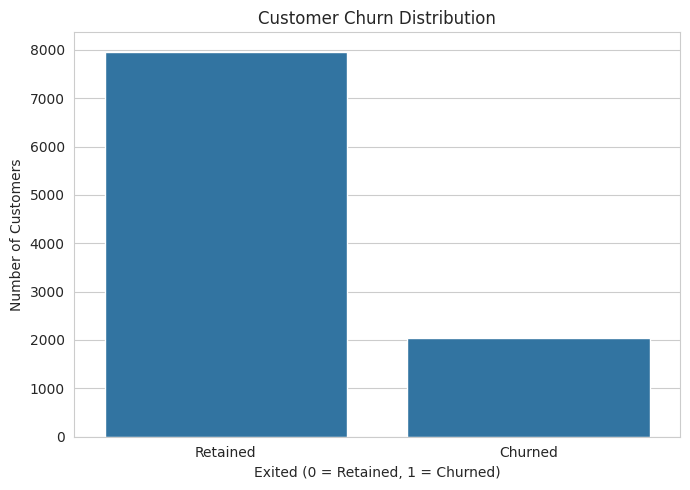

In [11]:
# STEP 5 - CUSTOMER CHURN DISTRIBUTION

# Count customers who stayed and exited
churn_counts = df['Exited'].value_counts()

print("CUSTOMER CHURN COUNTS:")
display(churn_counts)

# Calculate percentages
churn_percentages = df['Exited'].value_counts(normalize=True) * 100

print("\nCUSTOMER CHURN PERCENTAGES:")
display(churn_percentages.round(2))

# Visualize churn distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Exited')

plt.title('Customer Churn Distribution')
plt.xlabel('Exited (0 = Retained, 1 = Churned)')
plt.ylabel('Number of Customers')
plt.xticks([0, 1], ['Retained', 'Churned'])
plt.tight_layout()
plt.show()

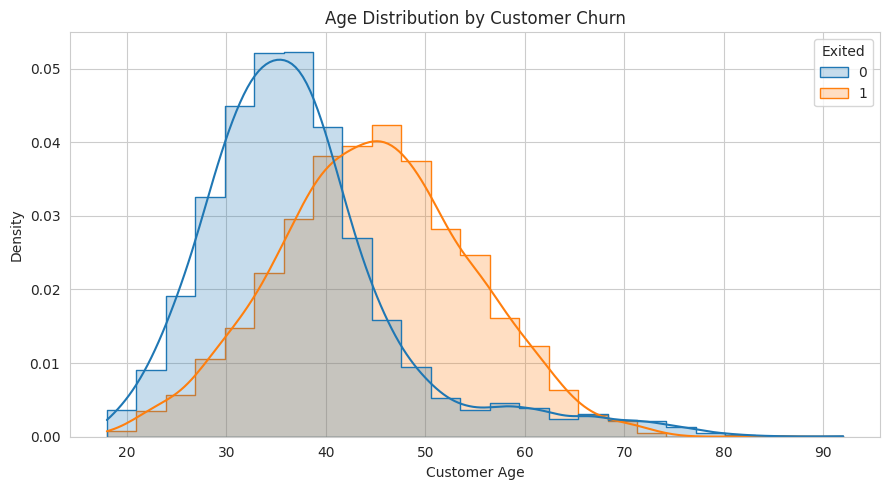

AVERAGE AGE BY CHURN STATUS:


,Age
Exited,
0,37.408389
1,44.837997



Retained customers (0) average age: 37.41
Churned customers (1) average age: 44.84


In [12]:
# STEP 6 - CHURN ANALYSIS BY AGE

# Compare age distributions of retained and churned customers
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Age',
    hue='Exited',
    bins=25,
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('Age Distribution by Customer Churn')
plt.xlabel('Customer Age')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

# Calculate average age by churn status
age_summary = df.groupby('Exited')['Age'].mean()

print("AVERAGE AGE BY CHURN STATUS:")
display(age_summary)

print("\nRetained customers (0) average age:", round(age_summary[0], 2))
print("Churned customers (1) average age:", round(age_summary[1], 2))

CHURN RATE BY GEOGRAPHY (%)


,Exited
Geography,
France,16.15
Germany,32.44
Spain,16.67


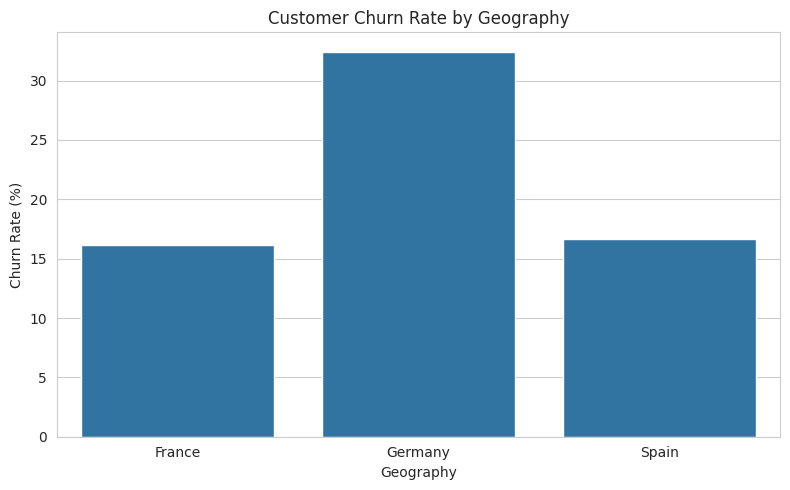


CHURN RATE BY GENDER (%)


,Exited
Gender,
Female,25.07
Male,16.46


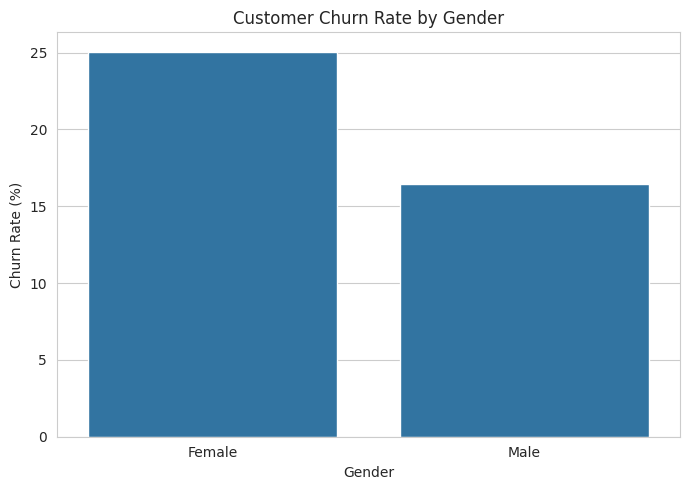

In [13]:
# STEP 7 - CHURN BY GEOGRAPHY AND GENDER

# Calculate churn rate by Geography
geo_churn = df.groupby('Geography')['Exited'].mean() * 100

print("CHURN RATE BY GEOGRAPHY (%)")
display(geo_churn.round(2))

# Visualize Geography
plt.figure(figsize=(8, 5))
sns.barplot(x=geo_churn.index, y=geo_churn.values)

plt.title('Customer Churn Rate by Geography')
plt.xlabel('Geography')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

# Calculate churn rate by Gender
gender_churn = df.groupby('Gender')['Exited'].mean() * 100

print("\nCHURN RATE BY GENDER (%)")
display(gender_churn.round(2))

# Visualize Gender
plt.figure(figsize=(7, 5))
sns.barplot(x=gender_churn.index, y=gender_churn.values)

plt.title('Customer Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

CHURN RATE BY TENURE (%)


,Exited
Tenure,
0,23.00
1,22.42
2,19.18
3,21.11
4,20.53
5,20.65
6,20.27
7,17.22
8,19.22


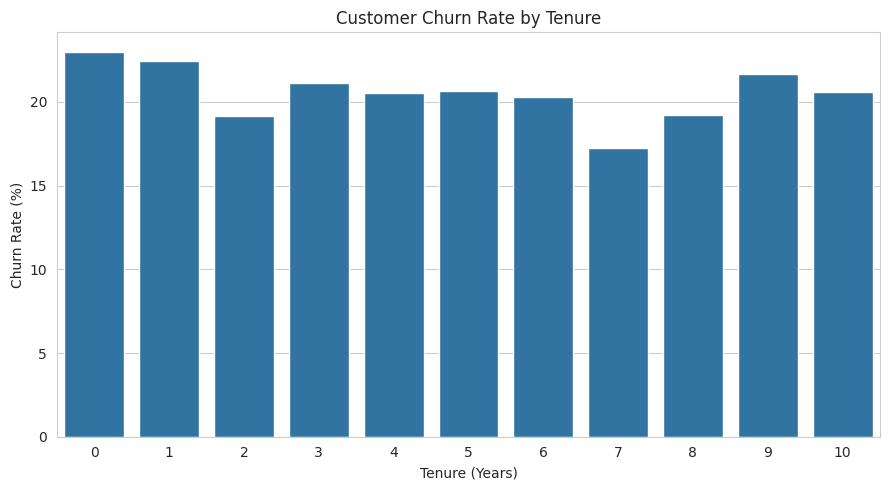


CHURN RATE BY BALANCE GROUP (%)


,Exited
BalanceGroup,
Zero Balance,13.82
0-50K,34.67
50-100K,19.88
100-150K,25.77
150-200K,21.93
200K+,55.88


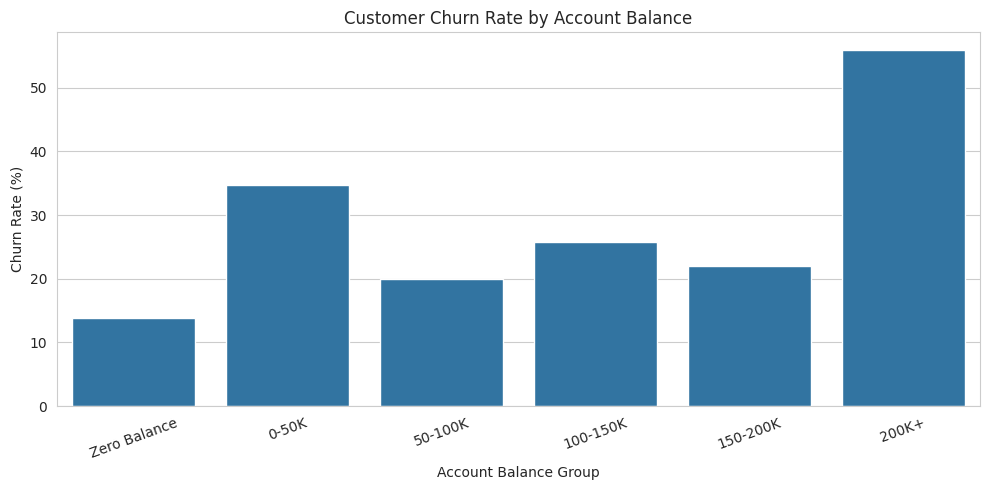


CHURN RATE BY NUMBER OF PRODUCTS (%)


,Exited
NumOfProducts,
1,27.71
2,7.58
3,82.71
4,100.00


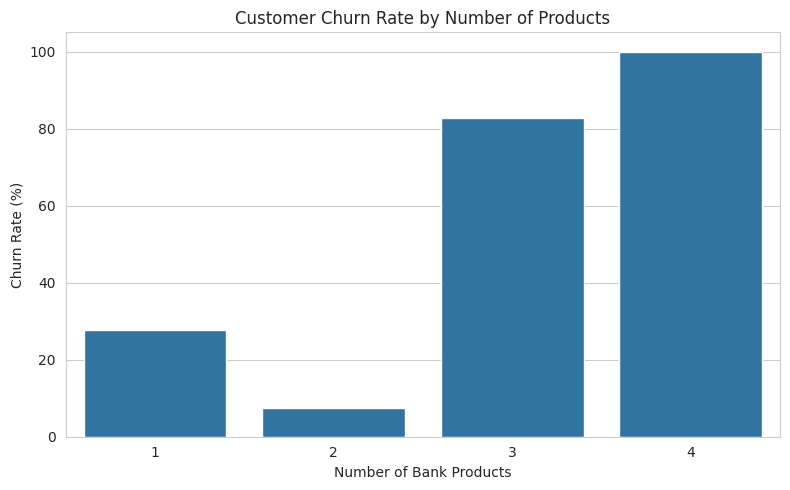

In [14]:
# STEP 8 - CHURN BY TENURE, BALANCE AND PRODUCTS

# 1. CHURN BY TENURE
tenure_churn = df.groupby('Tenure')['Exited'].mean() * 100

print("CHURN RATE BY TENURE (%)")
display(tenure_churn.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(x=tenure_churn.index, y=tenure_churn.values)

plt.title('Customer Churn Rate by Tenure')
plt.xlabel('Tenure (Years)')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

# 2. CHURN BY BALANCE
df['BalanceGroup'] = pd.cut(
    df['Balance'],
    bins=[-1, 0, 50000, 100000, 150000, 200000, float('inf')],
    labels=['Zero Balance', '0-50K', '50-100K', '100-150K', '150-200K', '200K+']
)

balance_churn = df.groupby('BalanceGroup', observed=False)['Exited'].mean() * 100

print("\nCHURN RATE BY BALANCE GROUP (%)")
display(balance_churn.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(x=balance_churn.index, y=balance_churn.values)

plt.title('Customer Churn Rate by Account Balance')
plt.xlabel('Account Balance Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 3. CHURN BY NUMBER OF PRODUCTS
product_churn = df.groupby('NumOfProducts')['Exited'].mean() * 100

print("\nCHURN RATE BY NUMBER OF PRODUCTS (%)")
display(product_churn.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(x=product_churn.index, y=product_churn.values)

plt.title('Customer Churn Rate by Number of Products')
plt.xlabel('Number of Bank Products')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

CHURN RATE BY ACTIVE MEMBERSHIP (%)


,Exited
IsActiveMember,
0,26.85
1,14.27


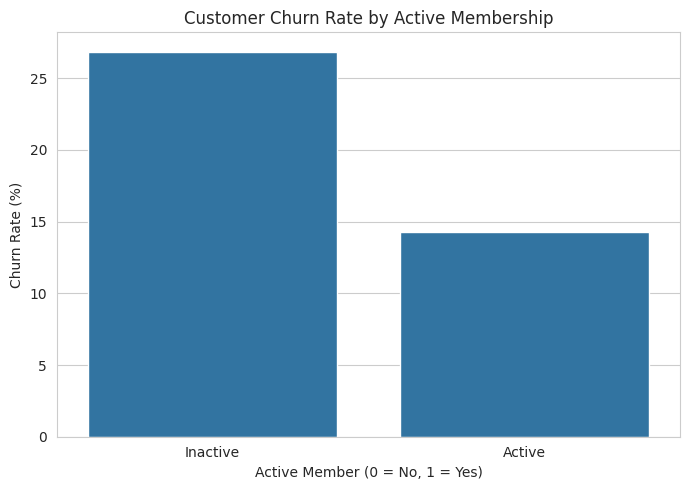


CHURN RATE BY CREDIT CARD OWNERSHIP (%)


,Exited
HasCrCard,
0,20.81
1,20.18


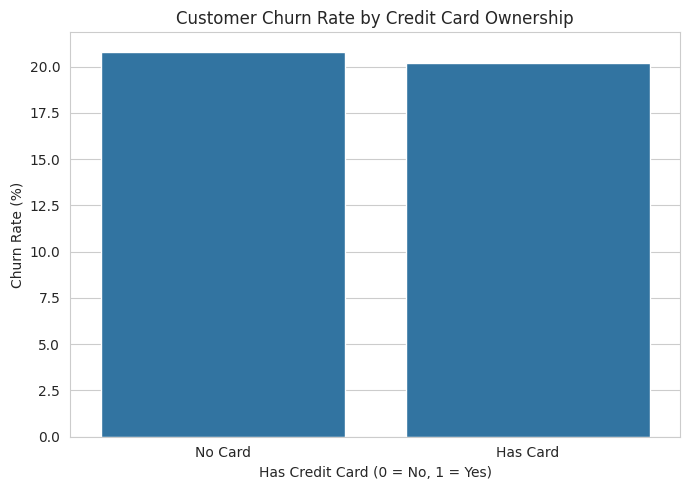

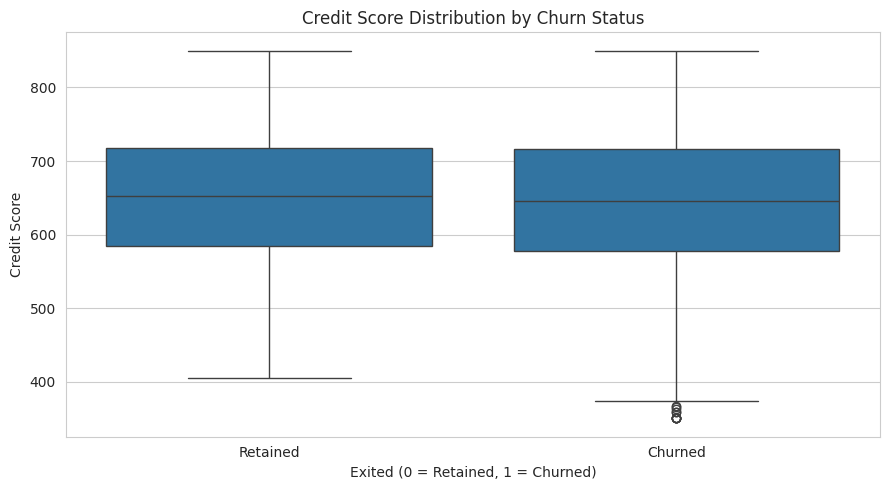


AVERAGE CREDIT SCORE BY CHURN STATUS


,CreditScore
Exited,
0,651.85
1,645.35



CHURN RATE BY SALARY GROUP (%)


,Exited
SalaryGroup,
Very Low,20.15
Low,19.82
Medium,20.06
High,20.21
Very High,21.61


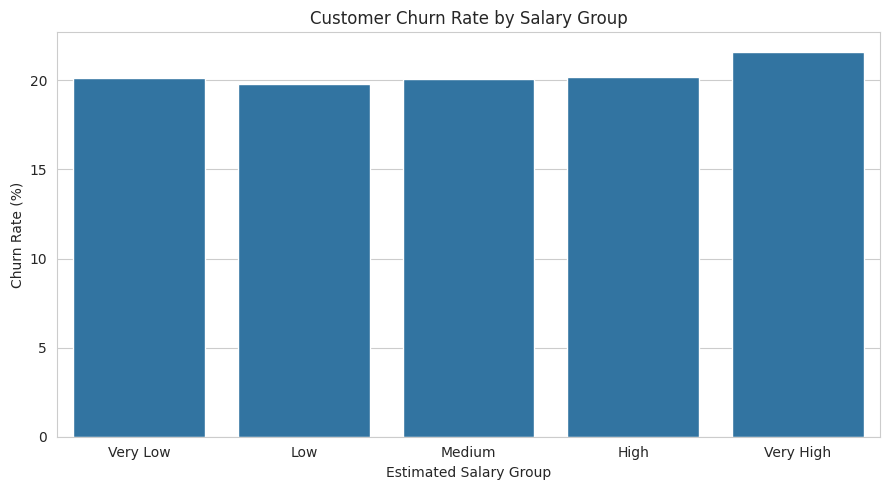

In [15]:
# STEP 9 - CHURN BY ACTIVITY, CREDIT CARD, CREDIT SCORE & SALARY

# 1. CHURN BY ACTIVE MEMBERSHIP
activity_churn = df.groupby('IsActiveMember')['Exited'].mean() * 100

print("CHURN RATE BY ACTIVE MEMBERSHIP (%)")
display(activity_churn.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(x=activity_churn.index, y=activity_churn.values)

plt.title('Customer Churn Rate by Active Membership')
plt.xlabel('Active Member (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate (%)')
plt.xticks([0, 1], ['Inactive', 'Active'])
plt.tight_layout()
plt.show()

# 2. CHURN BY CREDIT CARD OWNERSHIP
card_churn = df.groupby('HasCrCard')['Exited'].mean() * 100

print("\nCHURN RATE BY CREDIT CARD OWNERSHIP (%)")
display(card_churn.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(x=card_churn.index, y=card_churn.values)

plt.title('Customer Churn Rate by Credit Card Ownership')
plt.xlabel('Has Credit Card (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate (%)')
plt.xticks([0, 1], ['No Card', 'Has Card'])
plt.tight_layout()
plt.show()

# 3. CHURN BY CREDIT SCORE
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Exited', y='CreditScore')

plt.title('Credit Score Distribution by Churn Status')
plt.xlabel('Exited (0 = Retained, 1 = Churned)')
plt.ylabel('Credit Score')
plt.xticks([0, 1], ['Retained', 'Churned'])
plt.tight_layout()
plt.show()

print("\nAVERAGE CREDIT SCORE BY CHURN STATUS")
display(df.groupby('Exited')['CreditScore'].mean().round(2))

# 4. CHURN BY ESTIMATED SALARY
df['SalaryGroup'] = pd.cut(
    df['EstimatedSalary'],
    bins=5,
    labels=['Very Low', 'Low', 'Medium', 'High', 'Very High']
)

salary_churn = df.groupby('SalaryGroup', observed=False)['Exited'].mean() * 100

print("\nCHURN RATE BY SALARY GROUP (%)")
display(salary_churn.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(x=salary_churn.index, y=salary_churn.values)

plt.title('Customer Churn Rate by Salary Group')
plt.xlabel('Estimated Salary Group')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

In [16]:
# STEP 10 - PREPARE CLEAN DATASET FOR MACHINE LEARNING

# Create a separate copy so the original dataset remains unchanged
df_clean = df.copy()

# Remove customer identifiers and temporary EDA categories
columns_to_drop = ['CustomerId', 'Surname', 'BalanceGroup', 'SalaryGroup']

df_clean.drop(columns=columns_to_drop, errors='ignore', inplace=True)

# Check whether Year is constant
if 'Year' in df_clean.columns and df_clean['Year'].nunique() == 1:
    df_clean.drop(columns=['Year'], inplace=True)
    print("Year column removed because it contains only one unique value.")

# Display cleaned dataset
print("Cleaned dataset created successfully!")
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining columns:")
print(df_clean.columns.tolist())

print("\nFirst 5 rows of cleaned dataset:")
display(df_clean.head())

Year column removed because it contains only one unique value.
Cleaned dataset created successfully!
Cleaned dataset shape: (10000, 11)

Remaining columns:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

First 5 rows of cleaned dataset:


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [17]:
# STEP 11 - SAVE CLEANED DATASET

# Save the cleaned data as a CSV file
df_clean.to_csv('Bank_Churn_Cleaned.csv', index=False)

print("Cleaned dataset saved successfully!")
print("File name: Bank_Churn_Cleaned.csv")

Cleaned dataset saved successfully!
File name: Bank_Churn_Cleaned.csv


In [19]:
from google.colab import files

files.download('Bank_Churn_Cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>